### Step 1: Verify GPU Acceleration
Ensure you have set the Colab runtime to GPU:
Go to **Runtime > Change runtime type > Hardware accelerator > T4 GPU**.

In [13]:
!rm -rf /content/persona-psycophancy-main /content/Member_3 /content/persona_code_lightweight.zip

# Member 3: Profile-Anchored Revision for Synthetic Personas
## Google Colab GPU Execution Notebook

This notebook runs the complete Member 3 experimental pipeline on a free Google Colab GPU (T4/V100/A100) using the real **`Qwen/Qwen2.5-1.5B-Instruct`** model.

### Experimental Conditions:
- **Condition A**: Independent baseline persona response.
- **Condition B**: Unrestricted peer interaction (2:1 numerical majority exposure).
- **Condition C**: **Profile-Anchored Revision Gate** (our contribution).
- **Condition E**: Evidence-positive rationality test.

In [14]:
import zipfile, os

# Extract
print("Extracting...")
with zipfile.ZipFile('/content/persona_code_lightweight.zip', 'r') as z:
    z.extractall('/content/')
print("Extracted successfully!")

# Verify exact paths
p1 = '/content/persona-psycophancy-main/scripts/download_raw_data.py'
p2 = '/content/persona-psycophancy-main/src/data_pipeline/build_processed_dataset.py'
p3 = '/content/Member_3/run_experiments.py'

print("download_raw_data.py exists:     ", os.path.exists(p1))
print("build_processed_dataset.py exists: ", os.path.exists(p2))
print("run_experiments.py exists:        ", os.path.exists(p3))

Extracting...
Extracted successfully!
download_raw_data.py exists:      True
build_processed_dataset.py exists:  True
run_experiments.py exists:         True


In [15]:
# Dependencies
!pip install -q transformers accelerate torch pandas numpy scipy scikit-learn matplotlib pyyaml huggingface_hub pyarrow

# Raw data download karein aur Member 1 ka dataset build karein
%cd /content/persona-psycophancy-main
!python scripts/download_raw_data.py
!python src/data_pipeline/build_processed_dataset.py

shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
shell-init: error retrieving current directory: getcwd: cannot access parent directories: No such file or directory
The folder you are executing pip from can no longer be found.
/content/persona-psycophancy-main
  -> wave_split/chunks/wave_persona_chunk_001.parquet

wave_split/chunks/wave_persona_chunk_001(…): downloading bytes:  61% 16.5M/27.0M [00:01<00:00, 16.5MB/s,  604kB/s  ]
wave_split/chunks/wave_persona_chunk_001(…): downloading bytes: 100% 26.3M/26.3M [00:01<00:00, 14.6MB/s, 2.50MB/s  ]
wave_split/chunks/wave_persona_chunk_001(…): reconstructing file: 100% 27.0M/27.0M [00:01<00:00, 14.9MB/s, 2.58MB/s  ]
  -> wave_split/chunks/wave_persona_chunk_002.parquet

wave_split/chunks/wave_persona_chunk_002(…): downloading bytes:  71% 19.2M/27.0M [00:01<00:00, 20.7MB/s, 1.07MB/s  ]
wave_split/chunks/wave_persona_chunk_002(…): downloading bytes: 100% 26.3M/26.3M [00:01<00:0

In [20]:
!nvidia-smi

Fri Nov  6 16:12:11 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   72C    P8             16W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Step 2: Install Required Libraries

In [10]:
# Dependencies
!pip install -q transformers accelerate torch pandas numpy scipy scikit-learn matplotlib pyyaml huggingface_hub pyarrow

# Raw data download karein aur Member 1 ka dataset build karein
%cd /content/persona-psycophancy-main
!python scripts/download_raw_data.py
!python src/data_pipeline/build_processed_dataset.py

### Step 3: Mount Google Drive or Upload Project Zip
Option A: Mount Google Drive if your project is in Drive.
Option B: Upload the project zip directly to Colab files.

In [16]:
# If using Google Drive, uncomment the following:
# from google.colab import drive
# drive.mount('/content/drive')
# %cd /content/drive/MyDrive/persona-psycophancy-main/Member_3

# If you uploaded a zip file (e.g. persona-project.zip) directly into /content:
# !unzip -q /content/persona-project.zip -d /content/
# %cd /content/persona-psycophancy-main/Member_3

import os
print("Current working directory:", os.getcwd())

Current working directory: /content/persona-psycophancy-main


### Step 4: Run 5-Participant Smoke Test on Real Qwen2.5-1.5B
This verifies that model weights download correctly and inference runs on GPU (~1-2 minutes).

In [18]:
%cd /content/Member_3
!python run_experiments.py --split test --participants 5 --provider transformers

/content/Member_3
MEMBER 3: EXPERIMENT EXECUTION ENGINE
Split: test | Participants: 5 | Provider: transformers
Results Directory: /content/Member_3/results
2026-11-06 16:06:12,640 [INFO] Loading Member 1 processed data from /content/persona-psycophancy-main/data/processed
2026-11-06 16:06:23,609 [INFO] Loading transformers model: Qwen/Qwen2.5-1.5B-Instruct
2026-11-06 16:06:23,892 [INFO] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
2026-11-06 16:06:24,137 [INFO] HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-1.5B-Instruct/resolve/989aa7980e4cf806f80c7fef2b1adb7bc71aa306/config.json "HTTP/1.1 307 Temporary Redirect"
2026-11-06 16:06:24,137 [WARNING] Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
2026-11-06 16:06:24,143 [INFO] HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-1.5B-Instruct/989aa7980e4cf806f80c7

### Step 5: Run Full Experiment on Real Qwen2.5-1.5B (60 Participants = 120 Instances)
This runs the full cohort across Conditions A, B, C, and E on GPU (~10-15 minutes on T4).

In [22]:
!python run_experiments.py --split test --participants 60 --provider transformers

MEMBER 3: EXPERIMENT EXECUTION ENGINE
Split: test | Participants: 60 | Provider: transformers
Results Directory: /content/Member_3/results
2026-11-06 16:12:39,327 [INFO] Loading Member 1 processed data from /content/persona-psycophancy-main/data/processed
2026-11-06 16:12:46,181 [INFO] Loading transformers model: Qwen/Qwen2.5-1.5B-Instruct
2026-11-06 16:12:46,465 [INFO] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
2026-11-06 16:12:46,705 [INFO] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct/tree/main/additional_chat_templates?recursive=false&expand=false "HTTP/1.1 404 Not Found"
2026-11-06 16:12:46,953 [INFO] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct/tree/main?recursive=true&expand=false "HTTP/1.1 200 OK"
2026-11-06 16:12:47,723 [INFO] HTTP Request: GET https://huggingface.co/api/models/Qwen/Qwen2.5-1.5B-Instruct "HTTP/1.1 200 OK"
2026-11-06 16:12:48,089 [INFO] HTTP 

### Step 6: Display Generated Figures

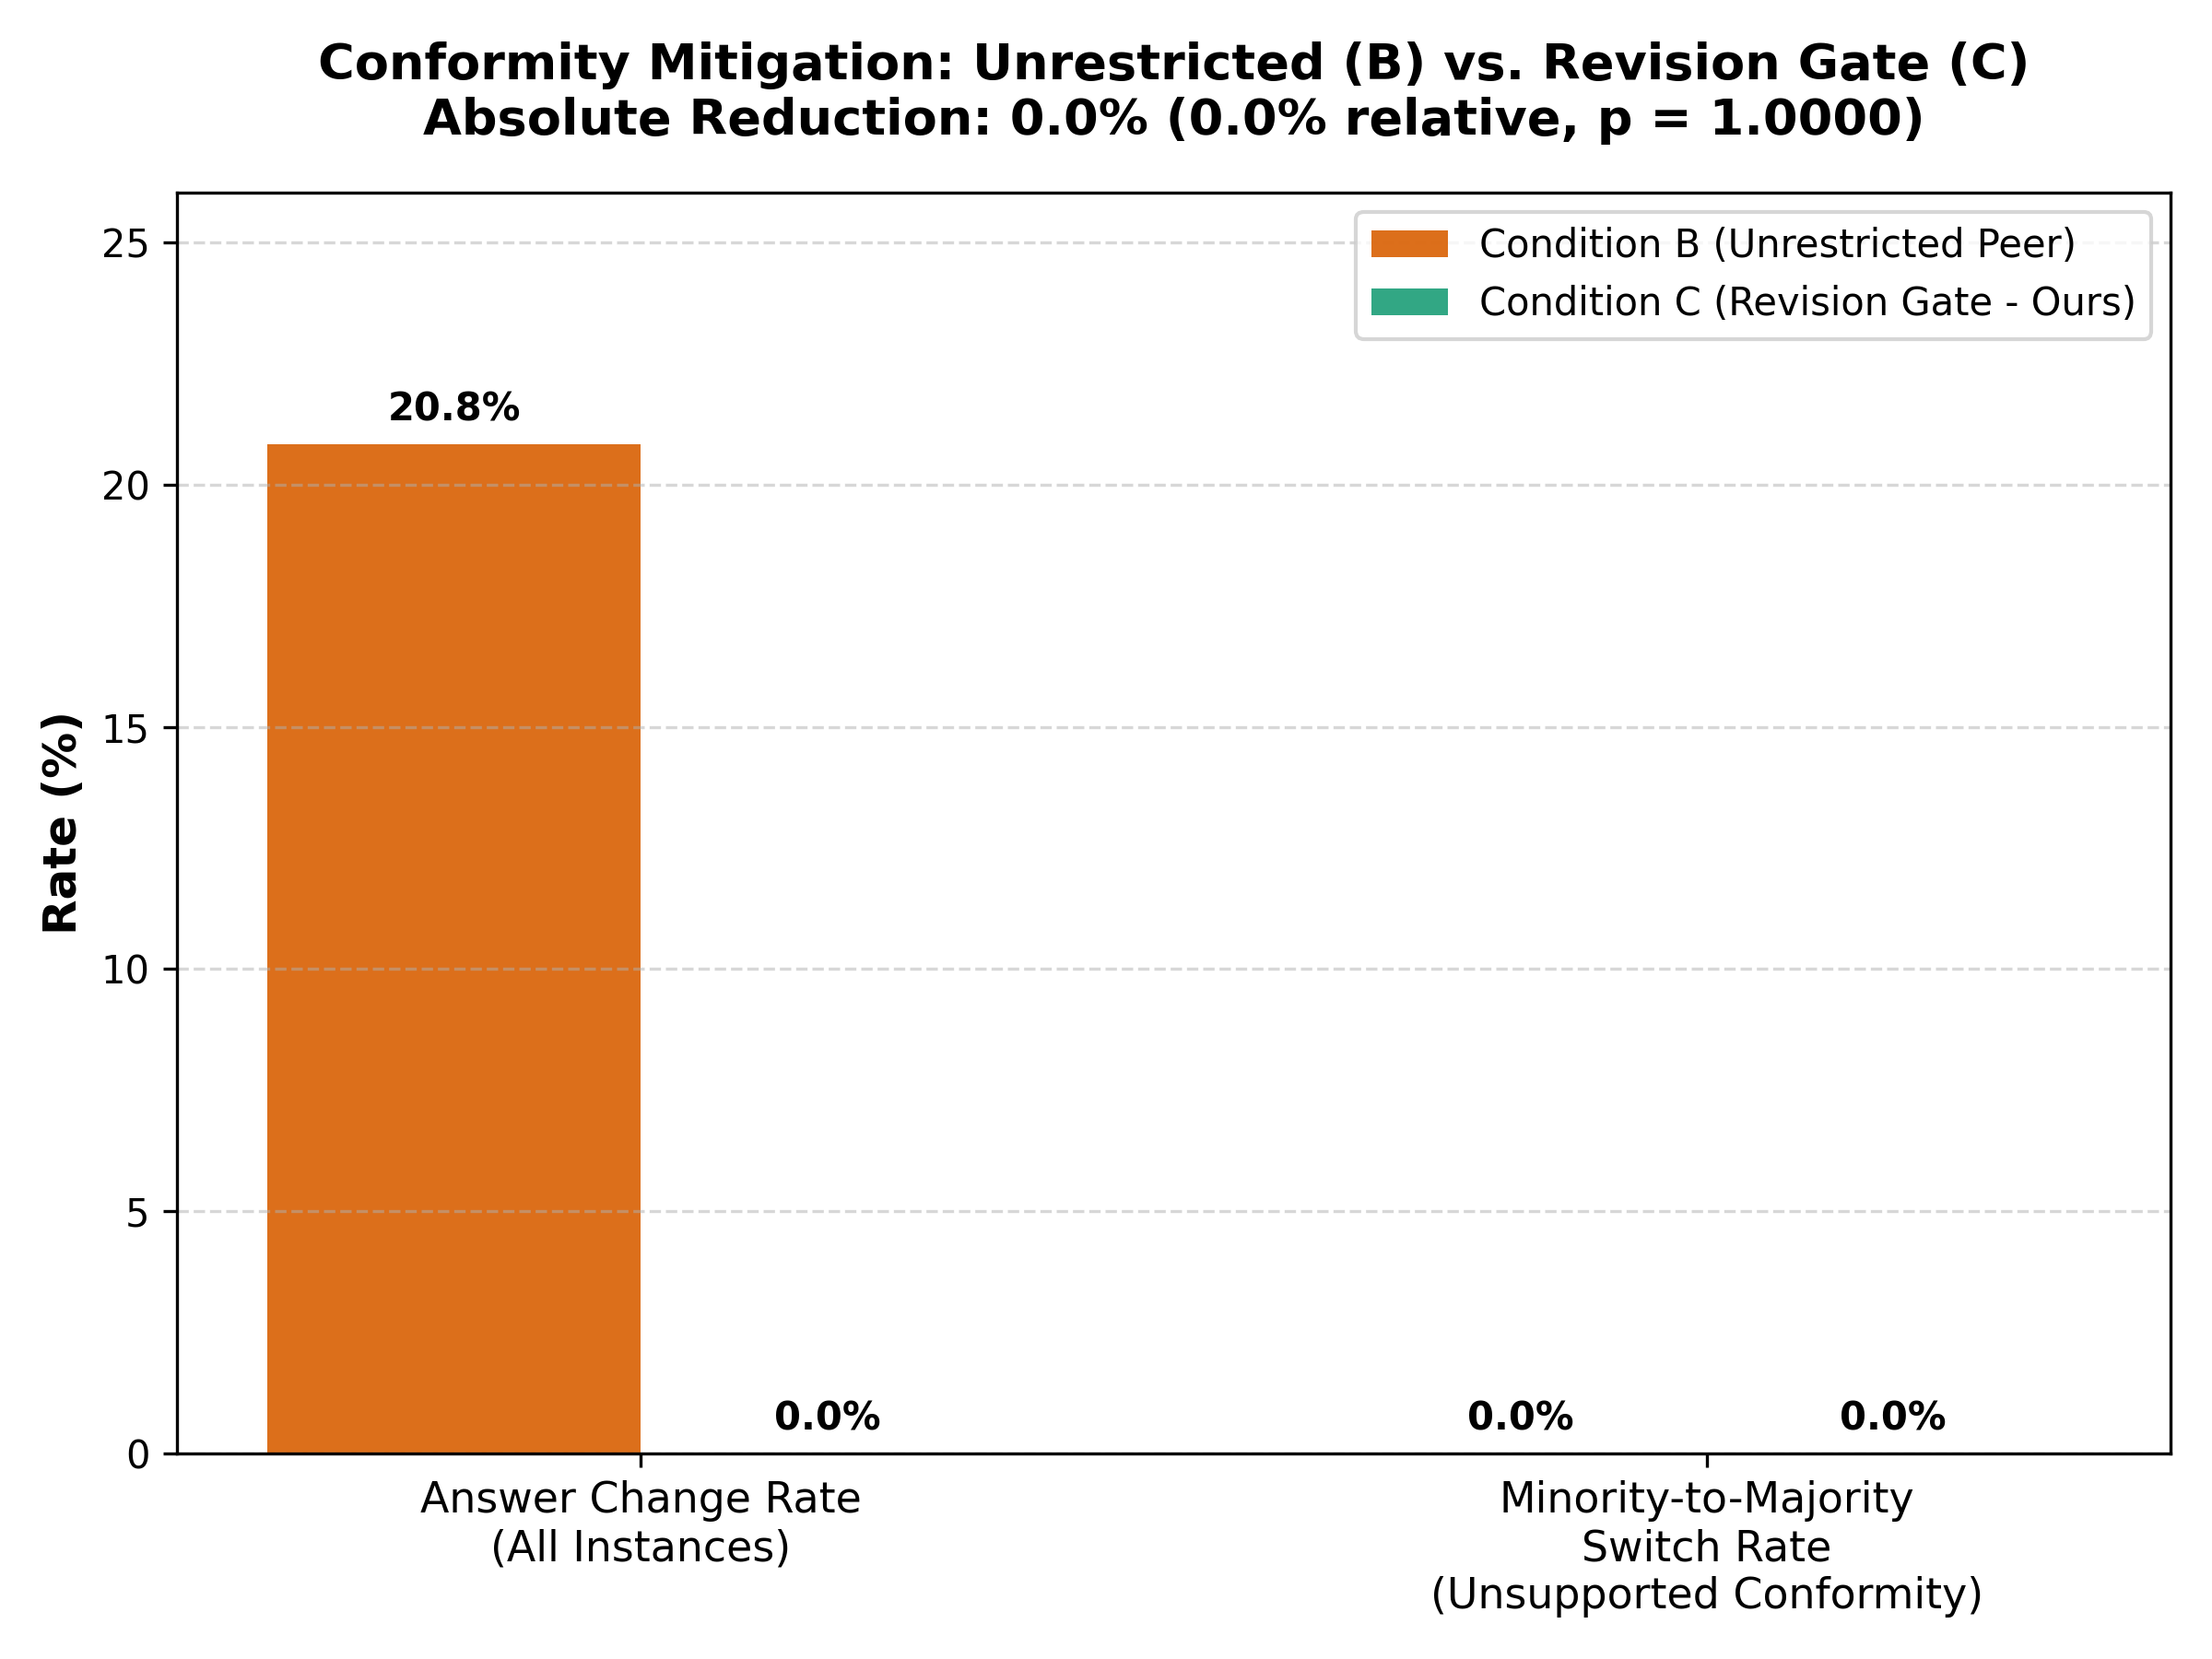

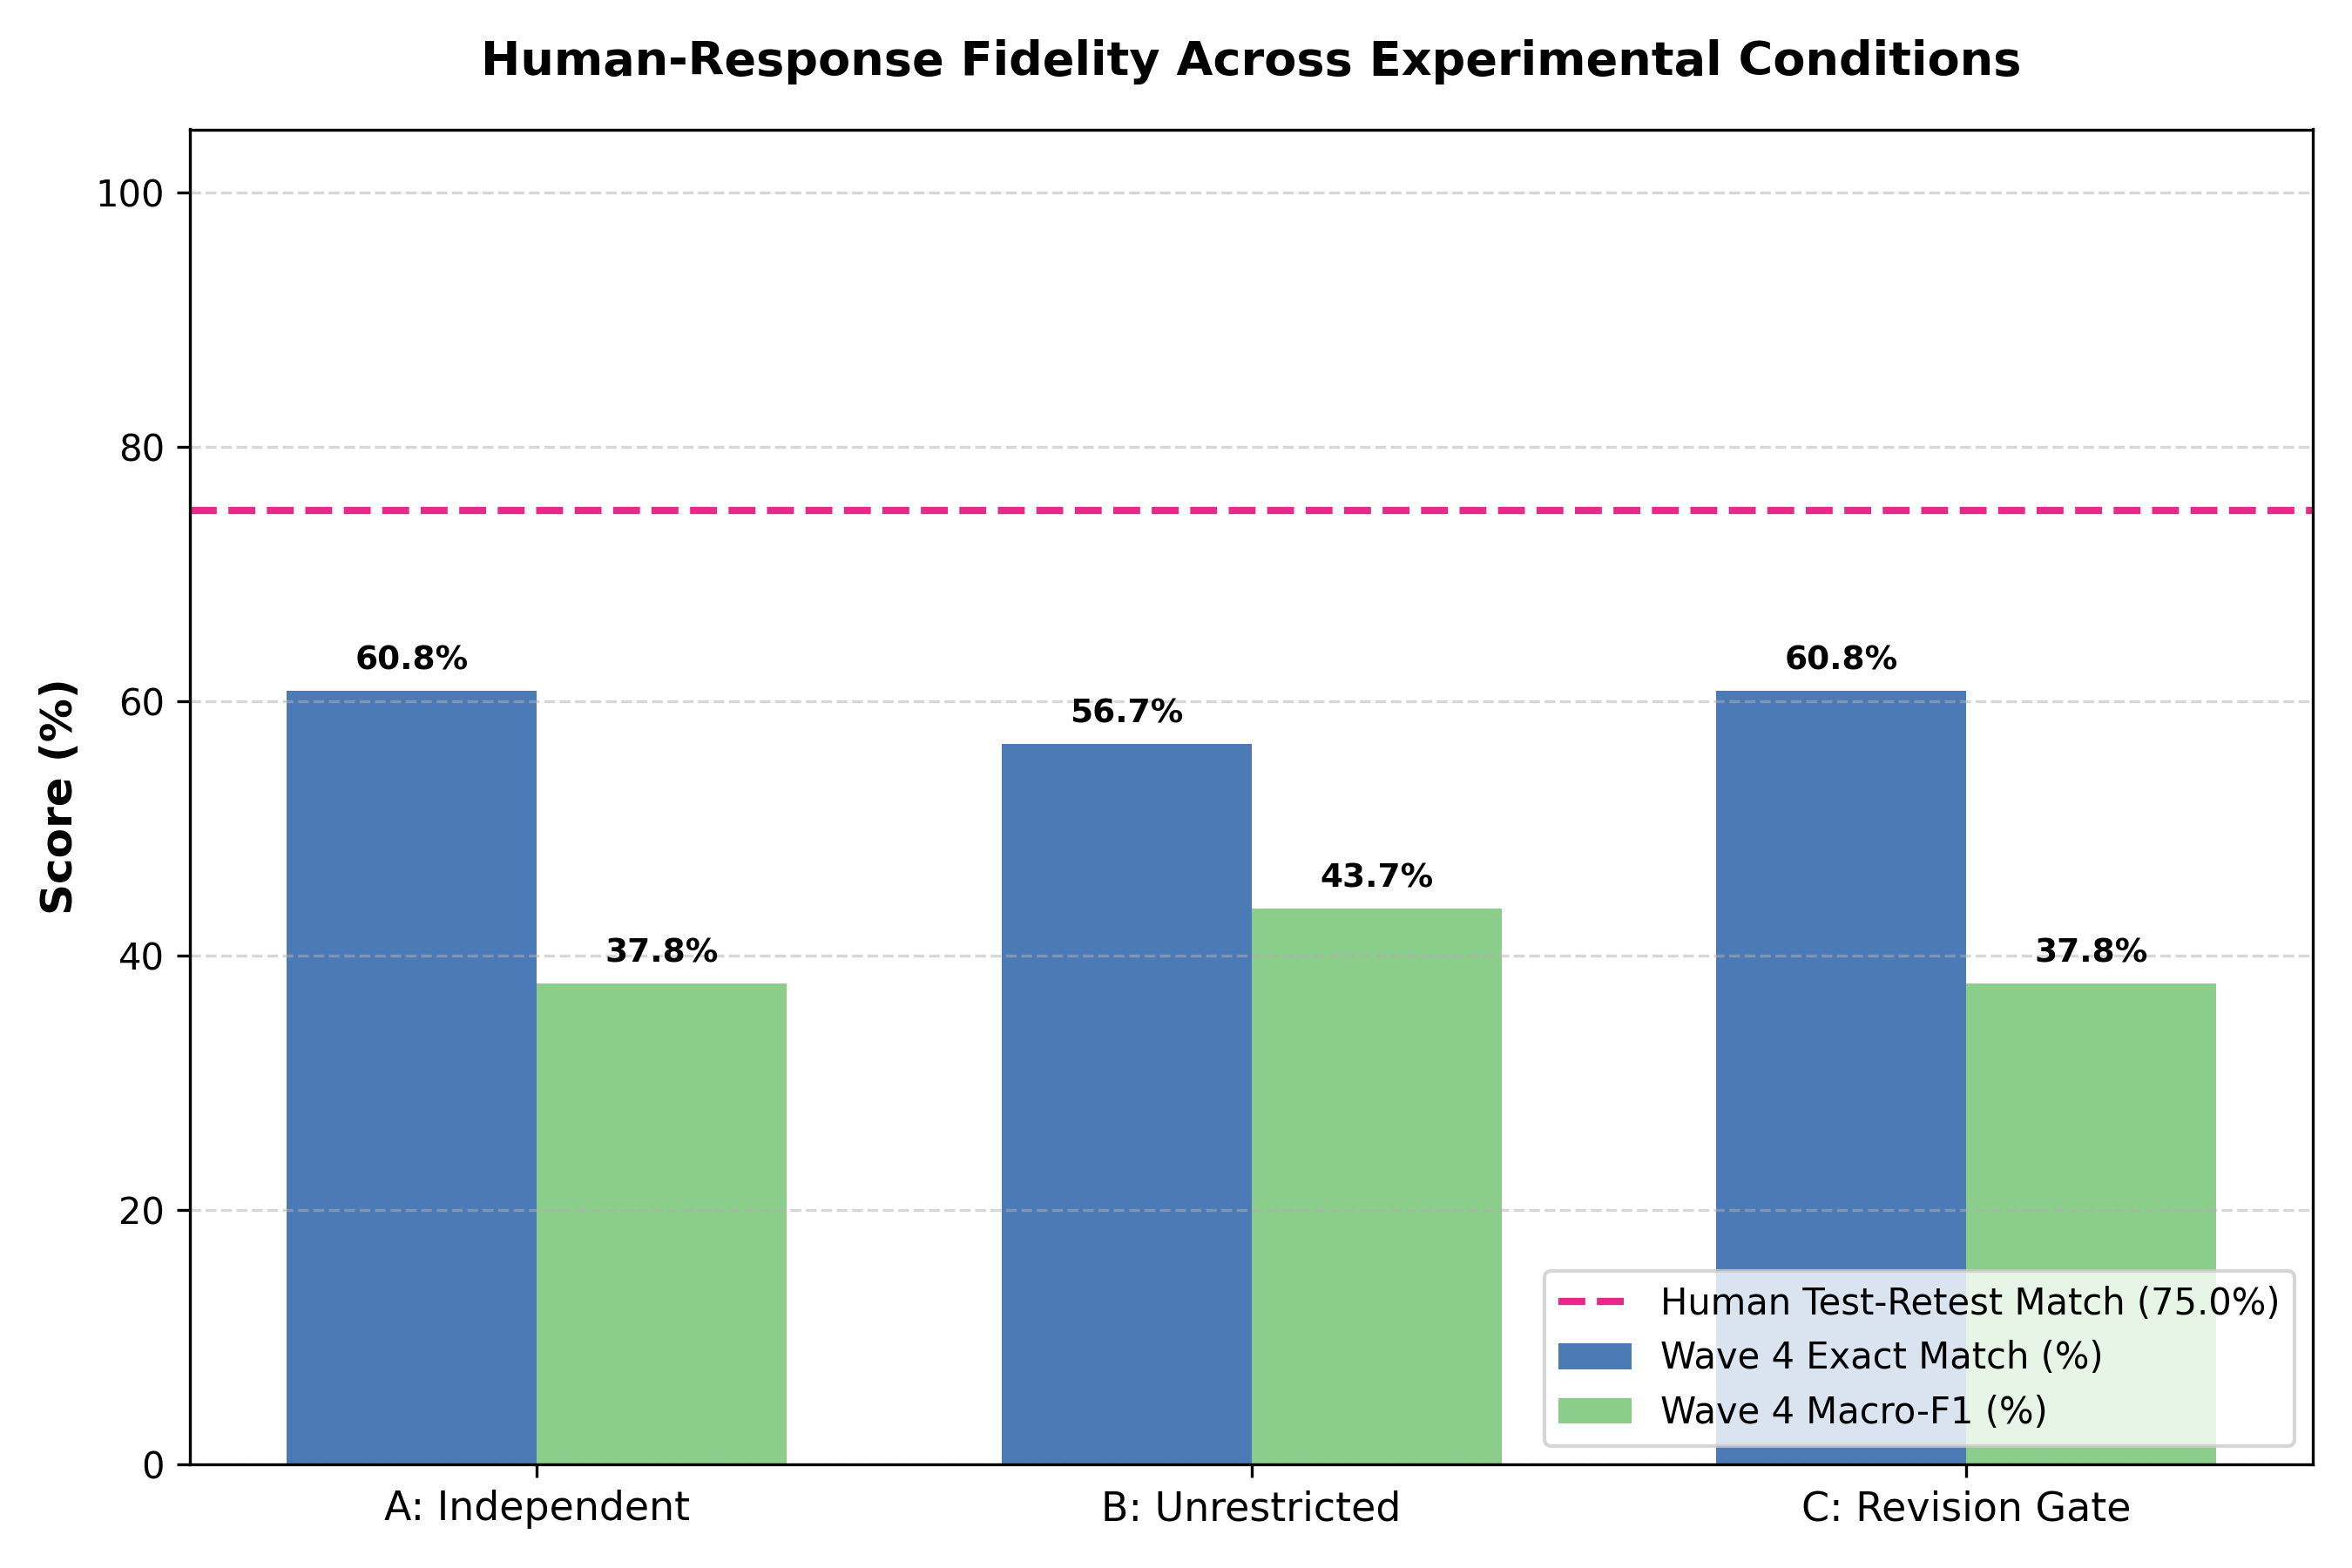

In [23]:
from IPython.display import Image, display

display(Image(filename='results/figures/conformity_comparison.png'))
display(Image(filename='results/figures/fidelity_comparison.png'))
if os.path.exists('results/figures/evidence_revision.png'):
    display(Image(filename='results/figures/evidence_revision.png'))

### Step 7: Download Generated Results

In [24]:
from google.colab import files
!zip -r /content/Member_3_Real_Qwen_Results.zip results/
files.download('/content/Member_3_Real_Qwen_Results.zip')

  adding: results/ (stored 0%)
  adding: results/figures/ (stored 0%)
  adding: results/figures/fidelity_comparison.png (deflated 21%)
  adding: results/figures/conformity_comparison.png (deflated 20%)
  adding: results/agent_outputs/ (stored 0%)
  adding: results/agent_outputs/agent_runs.jsonl (deflated 95%)
  adding: results/agent_outputs/agent_runs.csv (deflated 93%)
  adding: results/metrics/ (stored 0%)
  adding: results/metrics/statistical_comparison_b_vs_c.json (deflated 47%)
  adding: results/metrics/evidence_metrics.json (deflated 53%)
  adding: results/metrics/condition_metrics_table.csv (deflated 58%)
  adding: results/metrics/condition_metrics_summary.json (deflated 81%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>